In [1]:
import h5py
import pandas as pd
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, detrend, butter, filtfilt, stft, spectrogram
import h5py
from pathlib import Path
from datetime import datetime, timezone
import h5py
import numpy as np
from pathlib import Path
from scipy.signal import welch, detrend
import pandas as pd
import h5py
import numpy as np
from datetime import datetime, timezone
import os
from scipy.io import wavfile
from IPython.display import Audio, display

In [2]:
# =========================================================
# ANALYSIS SETTINGS -- set date/time once, everything below follows
# =========================================================

analysis_date = "20241108"   # YYYYMMDD
analysis_time = "200934"     # HHMMSS (UTC), matches a file's name
duration_s = 120.0            # seconds to load from analysis_time (or as many as available)

# 20241105 lives under MorroPhase; 20241106-20241112 under MorroPhase_base
dataset_config = "MorroPhase" if analysis_date == "20241105" else "MorroPhase_base"

dphi_dir = Path("/1-fnp/petasaur/p-jbod1/morro/Morro_SiteData") / dataset_config / analysis_date / "dphi"
fname = dphi_dir / f"{analysis_time}.hdf5"
start_time_str = (
    f"{analysis_date[0:4]}-{analysis_date[4:6]}-{analysis_date[6:8]} "
    f"{analysis_time[0:2]}:{analysis_time[2:4]}:{analysis_time[4:6]}"
)

print(f"dataset_config = {dataset_config}")
print(f"fname          = {fname}")
print(f"start_time_str = {start_time_str}")

dataset_config = MorroPhase_base
fname          = /1-fnp/petasaur/p-jbod1/morro/Morro_SiteData/MorroPhase_base/20241108/dphi/200934.hdf5
start_time_str = 2024-11-08 20:09:34


## Get metadata structure

In [3]:
# from pathlib import Path
# import h5py

# base = Path("/1-fnp/petasaur/p-jbod1/morro/Morro_SiteData")

# for folder in sorted(base.glob("*/20*/dphi")):

#     files = sorted(folder.glob("*.hdf5"))
#     if not files:
#         continue

#     fname = files[0]

#     print("\n" + "="*80)
#     print(folder.parent.parent.name)
#     print(fname.name)

#     with h5py.File(fname, "r") as fp:

#         def visitor(name, obj):

#             if isinstance(obj, h5py.Dataset):
#                 print(
#                     f"{name:60s} "
#                     f"shape={str(obj.shape):20s} "
#                     f"dtype={obj.dtype}"
#                 )

#         fp.visititems(visitor)

## Get metadata from all files

In [4]:

base = Path("/1-fnp/petasaur/p-jbod1/morro/Morro_SiteData")

records = []

for folder in sorted(base.glob("*/20*/dphi")):

    files = sorted(folder.glob("*.hdf5"))
    if not files:
        continue

    fname = files[0]

    with h5py.File(fname, "r") as fp:

        rec = {
            "configuration": folder.parent.parent.name,
            "date": folder.parent.name,
            "example_file": fname.name,
        }

        # Core DAS metadata
        rec["dt_s"] = fp["header/dt"][()]
        rec["fs_Hz"] = 1.0 / rec["dt_s"]
        rec["dx_m"] = fp["header/dx"][()]
        rec["gauge_length_m"] = fp["header/gaugeLength"][()]

        ns, nx = fp["data"].shape
        rec["n_samples"] = ns
        rec["n_channels"] = nx

        # Acquisition settings
        if "acqSpec" in fp:
            rec["acq_rate"] = fp["acqSpec/rate"][()]

        # Sweep settings
        if "sweepSpec" in fp:
            rec["sweep_rate"] = fp["sweepSpec/rate"][()]
            rec["sweep_bw"] = fp["sweepSpec/SBW"][()]
            rec["center_freq"] = fp["sweepSpec/freqCtr"][()]
            rec["char_rate"] = fp["sweepSpec/charRate"][()]
            rec["n_sweep"] = fp["sweepSpec/nSweep"][()]

            try:
                rec["sweep_name"] = fp["sweepSpec/sweepName"][()].decode()
            except:
                rec["sweep_name"] = str(fp["sweepSpec/sweepName"][()])

        records.append(rec)

df = pd.DataFrame(records)

cols = [
    "configuration",
    "date",
    "fs_Hz",
    "dx_m",
    "gauge_length_m",
    "n_channels",
    "sweep_bw",
    "center_freq",
    "char_rate",
    "n_sweep",
]

print(df[cols].to_string(index=False))

                configuration     date  fs_Hz   dx_m  gauge_length_m  n_channels   sweep_bw  center_freq   char_rate  n_sweep
                   MorroPhase 20241105 2000.0 1.0213       10.213002        9804 90000000.0  200000000.0 100000000.0     6000
              MorroPhase_base 20241106  500.0 1.0213       10.213002        9002 90000000.0  200000000.0 100000000.0     6000
              MorroPhase_base 20241107  500.0 1.0213       10.213002        9002 90000000.0  200000000.0 100000000.0     6000
              MorroPhase_base 20241108  500.0 1.0213       10.213002        9002 90000000.0  200000000.0 100000000.0     6000
              MorroPhase_base 20241109  500.0 1.0213       10.213002        9002 90000000.0  200000000.0 100000000.0     6000
              MorroPhase_base 20241110  500.0 1.0213       10.213002        9002 90000000.0  200000000.0 100000000.0     6000
              MorroPhase_base 20241111  500.0 1.0213       10.213002        9002 90000000.0  200000000.0 100000000.0  

In [5]:
summary = (
    df.groupby("configuration")
      .agg(
          start_date=("date", "min"),
          end_date=("date", "max"),
          fs_Hz=("fs_Hz", "first"),
          dx_m=("dx_m", "first"),
          gauge_length_m=("gauge_length_m", "first"),
          n_channels=("n_channels", "first"),
          n_sweep=("n_sweep", "first"),
      )
      .reset_index()
)

summary["date_range"] = summary.apply(
    lambda r: str(r.start_date)
    if r.start_date == r.end_date
    else f"{r.start_date}–{r.end_date}",
    axis=1,
)

print(
    summary[
        [
            "configuration",
            "date_range",
            "fs_Hz",
            "dx_m",
            "gauge_length_m",
            "n_channels",
            "n_sweep",
        ]
    ].to_string(index=False)
)

                configuration        date_range  fs_Hz   dx_m  gauge_length_m  n_channels  n_sweep
                   MorroPhase          20241105 2000.0 1.0213       10.213002        9804     6000
              MorroPhase_base 20241106–20241112  500.0 1.0213       10.213002        9002     6000
MorroPhase_sweep10us_gauge10m          20241106  500.0 1.0213       10.213002        9002     3000
MorroPhase_sweep40us_gauge10m          20241106  500.0 1.0213       10.213002        9002    12000
    MorroPhase_sweep_gauge10m          20241105  500.0 1.0213       10.213002        9002     6000
    MorroPhase_sweep_gauge20m          20241105  500.0 1.0213       20.426004        9002     6000
    MorroPhase_sweep_gauge40m 20241105–20241106  500.0 1.0213       40.852008        9002     6000


In [6]:

base = Path("/1-fnp/petasaur/p-jbod1/morro/Morro_SiteData/MorroPhase")

times = []

for fname in base.glob("*/dphi/*.hdf5"):

    try:
        with h5py.File(fname, "r") as fp:

            # only reliable timestamp in your dataset
            if "header/time" in fp:
                t = fp["header/time"][()]
                times.append(datetime.fromtimestamp(t, tz=timezone.utc))

    except Exception as e:
        print(f"Failed {fname.name}: {e}")

start_time = min(times)
end_time = max(times)

print("MorroPhase time range (UTC)")
print("Start:", start_time)
print("End  :", end_time)
print("Total files with time:", len(times))

MorroPhase time range (UTC)
Start: 2024-11-05 18:24:53.789000+00:00
End  : 2024-11-05 23:06:08.515000+00:00
Total files with time: 1649


In [7]:
# import h5py
# from pathlib import Path
# from datetime import datetime, timezone
# import pandas as pd

# folder = Path("/1-fnp/petasaur/p-jbod1/morro/Morro_SiteData/MorroPhase/20241105/dphi")

# records = []

# for fname in sorted(folder.glob("*.hdf5")):

#     with h5py.File(fname, "r") as fp:

#         rec = {"file": fname.name}

#         # ONLY reliable timestamp
#         t = fp["header/time"][()]
#         rec["time_utc"] = datetime.fromtimestamp(t, tz=timezone.utc)

#         records.append(rec)

# df = pd.DataFrame(records).sort_values("time_utc")

# print(df)

In [8]:
with h5py.File(fname, "r") as fp:

    t1 = fp.get("monitoring/Laser/startTime", None)
    t2 = fp.get("header/time", None)

    print("startTime exists:", t1 is not None)
    print("header/time exists:", t2 is not None)

    if t1 is not None:
        print("startTime raw:", t1[()])

    if t2 is not None:
        print("header/time raw:", t2[()])


with h5py.File(fname, "r") as fp:

    data = fp["data"][:].astype(np.float32)

    dt = fp["header/dt"][()]
    dx = fp["header/dx"][()]
    gl = fp["header/gaugeLength"][()]
    scale = fp["header/dataScale"][()]

    fs = 1 / dt

    data *= scale  # ✔ apply scaling here

    # -------------------------
    # UTC TIME EXTRACTION
    # -------------------------
    if "monitoring/Laser/startTime" in fp:
        t = fp["monitoring/Laser/startTime"][()]
        time_utc = datetime.fromtimestamp(t, tz=timezone.utc)

    elif "header/time" in fp:
        t = fp["header/time"][()]
        time_utc = datetime.fromtimestamp(t, tz=timezone.utc)

    else:
        time_utc = None

    print(f"time (UTC) = {time_utc}")
    print(f"fs = {fs:.1f} Hz")
    print(f"dx = {dx:.4f} m")
    print(f"GL = {gl:.2f} m")
    print(f"data shape = {data.shape}")

with h5py.File(fname,'r') as fp:

    print("unit =", fp["header/unit"][()])
    print("dataScale =", fp["header/dataScale"][()])
    print("sensorType =", fp["header/sensorType"][()])
    print("sensitivityUnits =", fp["header/sensitivityUnits"][:])

    print("processing unit =",
          fp["processingChain/step-0/data/unit"][()])

    print("time sf =",
          fp["processingChain/step-0/time/sf"][()])

startTime exists: True
header/time exists: True
startTime raw: 0
header/time raw: 1730847968.515
time (UTC) = 1970-01-01 00:00:00+00:00
fs = 2000.0 Hz
dx = 1.0213 m
GL = 10.21 m
data shape = (20000, 9804)
unit = b'rad/(s*m)'
dataScale = 0.07509940768355672
sensorType = [b'D']
sensitivityUnits = [b'rad/(strain*m)']
processing unit = b'rad/(s*m)'
time sf = 2000.0


## Load N seconds of data from a specified UTC start time

Overrides `data`/`fs`/`dx`/`dt`/`gl` above with up to `duration_s` (default 60s) of data
starting at `start_time_str`, spanning as many 10s files as needed. If the recording
ends before `duration_s` elapses (or has a gap), you get whatever's actually available
and a printed note saying so -- it won't error or silently pad with zeros.

`dphi_dir` picks which dataset/day to pull from -- point it at any `<config>/<date>/dphi`
folder from the `summary` table above (defaults to the 2000Hz MorroPhase/20241105 day
used elsewhere in this notebook).

Once this cell runs, re-run the waterfall / PSD-vs-channel / stacked-spectrogram cells
above (or below) -- they all just consume `data`, `fs`, `dx`, `dt`.

In [9]:
def load_time_range(start_time_str, duration_s, dphi_dir):
    """Load up to duration_s of data starting at start_time_str (UTC), spanning
    as many 10s files in dphi_dir as needed. Returns whatever's actually
    available if the recording ends (or has a gap) before duration_s elapses."""

    dphi_dir = Path(dphi_dir)
    date_str = dphi_dir.parent.name  # e.g. "20241105"

    start_dt = datetime.fromisoformat(start_time_str).replace(tzinfo=timezone.utc)
    start_epoch = start_dt.timestamp()

    day_files = sorted(dphi_dir.glob("*.hdf5"))
    if not day_files:
        raise FileNotFoundError(f"No files under {dphi_dir}")

    # Filenames are HHMMSS (UTC, whole seconds) matching header/time to within
    # ~1s -- use them to narrow down candidates *without* opening all N files
    # in the day (opening each is expensive on this mount; only the ~handful
    # that actually overlap the window need to be touched).
    nominal_times = np.array(
        [
            datetime.strptime(date_str + f.stem, "%Y%m%d%H%M%S")
            .replace(tzinfo=timezone.utc)
            .timestamp()
            for f in day_files
        ]
    )

    with h5py.File(day_files[0], "r") as fp:
        dt = fp["header/dt"][()]
        fs = 1 / dt
        dx = fp["header/dx"][()]
        gl = fp["header/gaugeLength"][()]
        scale = fp["header/dataScale"][()]
        file_duration = fp["data"].shape[0] * dt

    day_start = datetime.fromtimestamp(nominal_times[0], tz=timezone.utc)
    day_end = datetime.fromtimestamp(nominal_times[-1] + file_duration, tz=timezone.utc)

    margin = 2.0  # pad past filename's whole-second resolution
    candidates = np.where(
        (nominal_times + file_duration + margin > start_epoch)
        & (nominal_times - margin < start_epoch + duration_s)
    )[0]
    if len(candidates) == 0:
        raise ValueError(
            f"No data covers {start_dt} in {dphi_dir} "
            f"(recording spans {day_start} - {day_end})"
        )

    # exact header/time for just the candidates (cheap scalar reads)
    file_times = np.array(
        [h5py.File(day_files[i], "r")["header/time"][()] for i in candidates]
    )
    covers = (file_times + file_duration > start_epoch) & (file_times < start_epoch + duration_s)
    idx = candidates[covers]
    if len(idx) == 0:
        raise ValueError(
            f"No data covers {start_dt} in {dphi_dir} "
            f"(recording spans {day_start} - {day_end})"
        )
    file_times = file_times[covers]

    gaps = np.diff(file_times) - file_duration
    gap_tolerance_s = 0.05  # header/time has ~1ms jitter between otherwise-contiguous files
    if np.any(np.abs(gaps) > gap_tolerance_s):
        print(
            f"warning: gap(s) in source files within this window (up to {gaps.max():.2f}s) -- "
            f"concatenated trace will not be perfectly time-contiguous"
        )

    chunks = []
    for i in idx:
        with h5py.File(day_files[i], "r") as fp:
            chunks.append(fp["data"][:].astype(np.float32) * scale)
    full = np.concatenate(chunks, axis=0)

    offset = max(0, int(round((start_epoch - file_times[0]) * fs)))
    n_wanted = int(round(duration_s * fs))
    data = full[offset : offset + n_wanted]

    actual_start = file_times[0] + offset / fs
    time_utc = datetime.fromtimestamp(actual_start, tz=timezone.utc)
    actual_duration = data.shape[0] / fs

    if actual_duration < duration_s - dt:
        print(
            f"only {actual_duration:.1f}s available starting {time_utc} "
            f"(requested {duration_s:.0f}s; recording ends {day_end})"
        )
    else:
        print(f"loaded {actual_duration:.1f}s starting {time_utc}")

    return data, fs, dx, dt, gl, time_utc


# uses analysis_date/analysis_time/duration_s/dphi_dir from the settings cell at the top
data, fs, dx, dt, gl, time_utc = load_time_range(start_time_str, duration_s, dphi_dir)
print(f"data shape = {data.shape}, fs = {fs:.1f} Hz, dx = {dx:.4f} m")

loaded 120.0s starting 2024-11-08 20:09:33.999000+00:00
data shape = (60000, 9002), fs = 500.0 Hz, dx = 1.0213 m


In [10]:
data = detrend(data, axis=0)

In [11]:
## data is already capped to the requested duration by load_time_range() above;
## this just reports shape (no further truncation, so a 60s/2000Hz window isn't
## silently cut down to 50s the way a hardcoded 100k-sample cap would).
n_samples, n_channels = data.shape
print(f"n_samples={n_samples} ({n_samples/fs:.1f}s), n_channels={n_channels}")


n_samples=60000 (120.0s), n_channels=9002


In [12]:
##bandpass filter the data
# b,a = butter(2,200,'high',fs=1/dt)
# data_hf = filtfilt(b,a,data,axis=0)

#bandpass between 10 - 50 Hz
b,a = butter(2,[10,499],'bandpass',fs=1/dt)
data_bp = filtfilt(b,a,data,axis=0)


ValueError: Digital filter critical frequencies must be 0 < Wn < fs/2 (fs=500.0 -> fs/2=250.0)

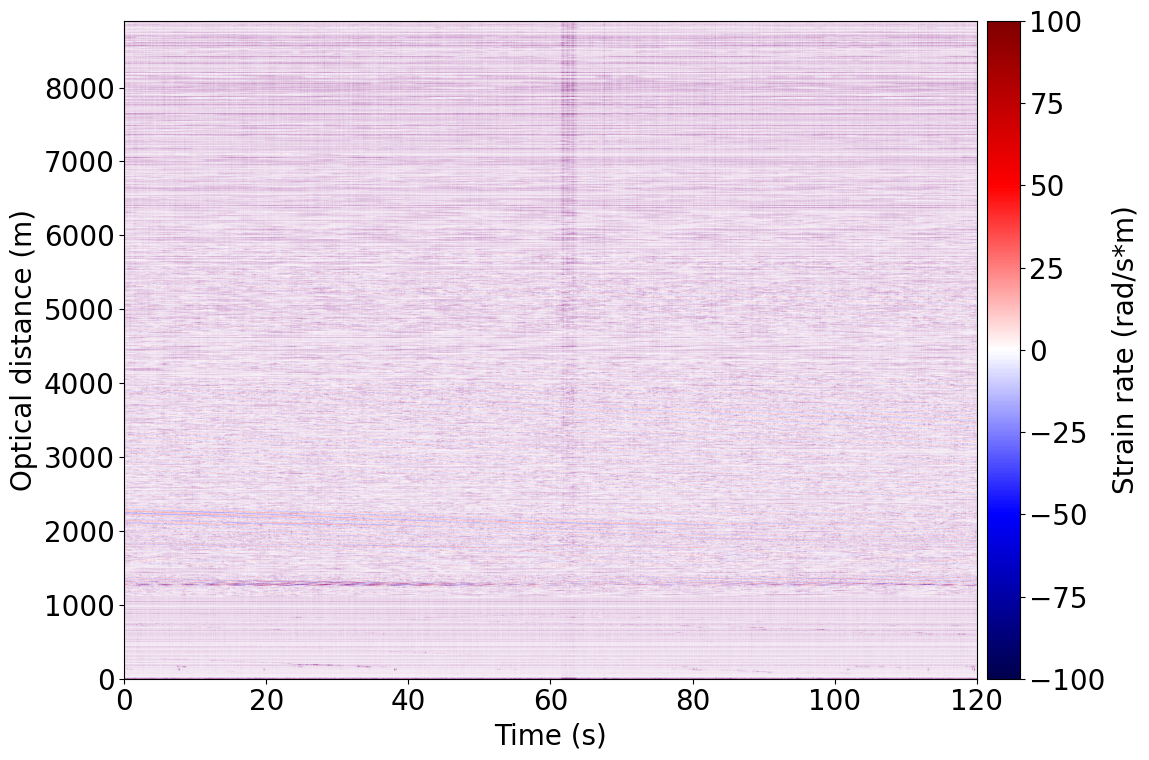

In [ ]:
plt.rcParams.update({'font.size': 20})
chan_step = 6

plt.figure(figsize=(12,8))

extent = [
    0,
    data.shape[0]/fs,
    data.shape[1]*dx,
    0
]

plt.imshow(
    data[:, ::chan_step].T,
    aspect="auto",
    extent=extent,
    cmap="seismic",
    vmin=-100,
    vmax=100
)

# plt.imshow(
#     data_bp[:, ::chan_step].T,
#     aspect="auto",
#     extent=extent,
#     cmap="seismic",
#     vmin=np.percentile(data_bp,1),
#     vmax=np.percentile(data_bp,99)
# )

plt.xlabel("Time (s)")
plt.ylim(0, 8900)
plt.ylabel("Optical distance (m)")
# plt.title("Spatio-temporal DAS data")

plt.colorbar(label="Strain rate (rad/s*m)", pad=0.01)
plt.tight_layout()
plt.show()

In [ ]:
# plt.rcParams.update({'font.size': 20})
# channels = np.arange(0, data.shape[1], 50)

# psds = []

# for ch in channels:

#     f, Pxx = welch(
#         data[:, ch],
#         fs=fs,
#         nperseg=2048
#     )

#     psds.append(10*np.log10(Pxx))

# psds = np.array(psds)

# plt.figure(figsize=(10,6))

# plt.imshow(
#     psds,
#     aspect="auto",
#     origin="lower",
#     extent=[f[0], f[-1], channels[0], channels[-1]],
#     vmin = np.percentile(psds,5),
#     vmax = np.percentile(psds,99)
# )

# plt.xlabel("Frequency (Hz)")
# plt.ylabel("Channel")
# plt.ylim(0, 8800)
# plt.title("PSD vs channel")

# plt.colorbar(label="PSD (dB)")
# plt.show()

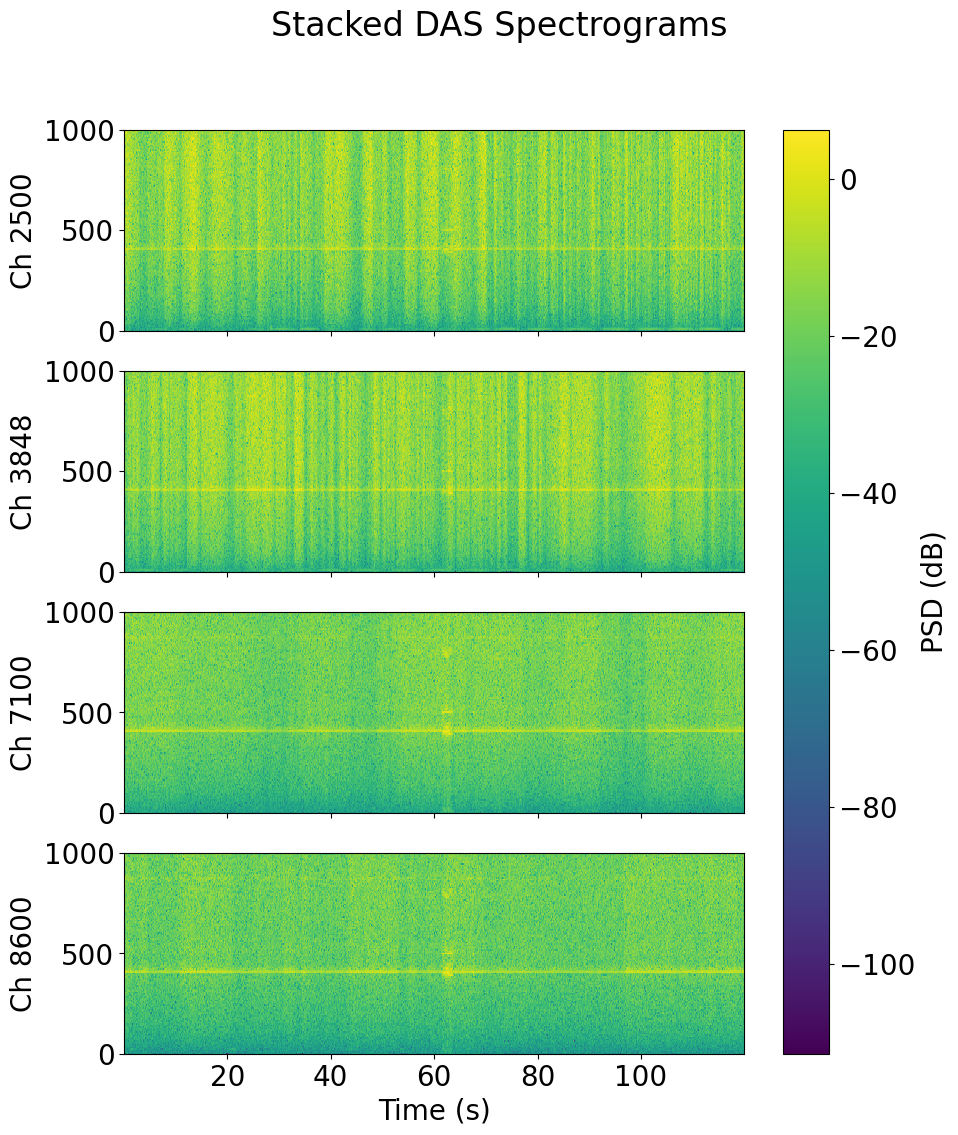

In [ ]:

# =========================================================
# Select several locations along the cable
# =========================================================

channels = [2500, 3848, 7100, 8600]

# stack +/- N channels around each center
stack_half_width = 3

# =========================================================
# Plot spectrograms
# =========================================================

fig, axes = plt.subplots(
    len(channels),
    1,
    figsize=(10, 12),
    sharex=True
)

for ax, ch in zip(axes, channels):

    i1 = max(0, ch - stack_half_width)
    i2 = min(data.shape[1], ch + stack_half_width + 1)

    # stack neighboring channels
    x = np.mean(data[:, i1:i2], axis=1)

    # detrend
    x = detrend(x)

    f, t, Sxx = spectrogram(
        x,
        fs=fs,
        nperseg=256,
        noverlap=0.80 * 256,
        scaling="density",
        mode="psd"
    )

    Sxx_db = 10 * np.log10(Sxx + 1e-20)
    # Sxx_db = Sxx_db - np.median(Sxx_db, axis=1, keepdims=True)  # remove median across frequency
    # Sxx_db = Sxx_db - np.percentile(Sxx_db, 50, axis=0, keepdims=True) # remove median across time

    im = ax.pcolormesh(
        t,
        f,
        Sxx_db,
        shading="auto",
        # vmin=np.percentile(Sxx_db, 50),
        # vmax=np.percentile(Sxx_db, 99)
    )

    ax.set_ylim(0, 1000)
    ax.set_ylabel(f"Ch {ch}")

axes[-1].set_xlabel("Time (s)")
plt.colorbar(im, ax=axes, label="PSD (dB)")
plt.suptitle("Stacked DAS Spectrograms")
# plt.tight_layout()
plt.show()

In [ ]:
files = sorted(base.glob("*/dphi/*.hdf5"))

/tmp/ipykernel_280806/2646465859.py:84: UserWarning: Adding colorbar to a different Figure <Figure size 1000x1200 with 5 Axes> than <Figure size 1400x1200 with 5 Axes> which fig.colorbar is called on.
  plt.colorbar(im, ax=axes, label="PSD (dB)")


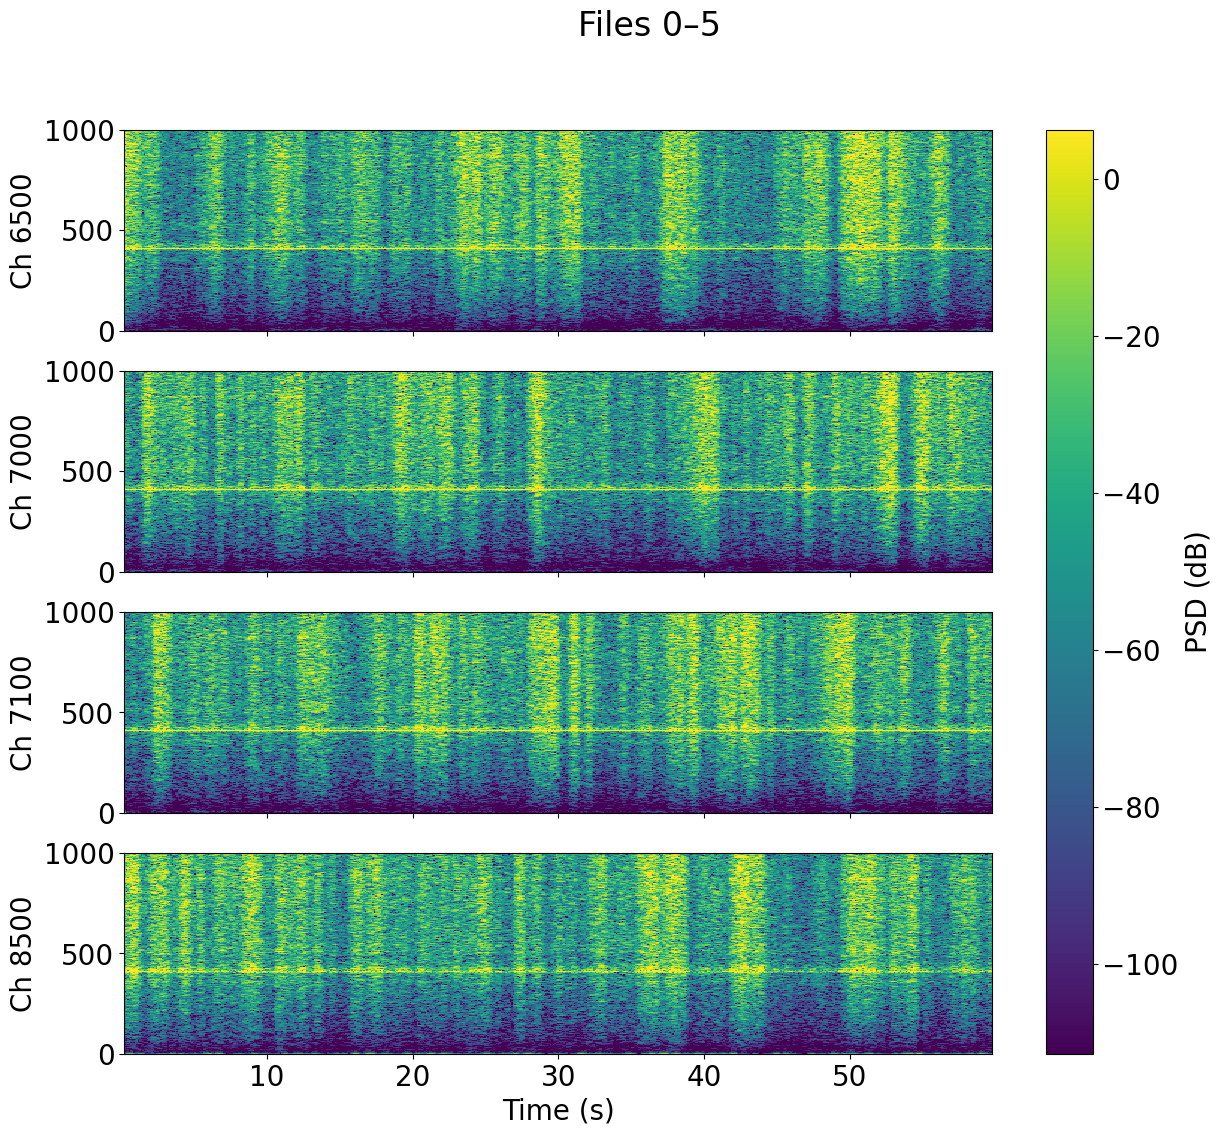

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram, detrend

# =========================================================
# Select 1-minute chunk (6 x 10-second files)
# =========================================================

start_file = 0      # change this
n_files = 6

channels = [6500, 7000, 7100, 8500]
stack_half_width = 10

# =========================================================
# Load and concatenate
# =========================================================

traces = {ch: [] for ch in channels}

for fname in files[start_file:start_file+n_files]:

    with h5py.File(fname, "r") as fp:

        scale = fp["header/dataScale"][()]
        dt = fp["header/dt"][()]
        fs = 1 / dt

        for ch in channels:

            i1 = max(0, ch - stack_half_width)
            i2 = min(fp["data"].shape[1], ch + stack_half_width + 1)

            x = fp["data"][:, i1:i2].astype(np.float32)
            x = np.mean(x, axis=1)

            traces[ch].append(x * scale)

# concatenate into ~1 minute
for ch in channels:
    traces[ch] = np.concatenate(traces[ch])
    traces[ch] = detrend(traces[ch])

# =========================================================
# Plot
# =========================================================

fig, axes = plt.subplots(
    len(channels),
    1,
    figsize=(14, 12),
    sharex=True
)
nperseg = 1024
noverlap = int(0.80 * nperseg)

for ax, ch in zip(axes, channels):

    f, t, Sxx = spectrogram(
        traces[ch],
        fs=fs,
        nperseg=nperseg,
        noverlap=noverlap,
        scaling="density"
    )

    Sxx_db = 10*np.log10(Sxx + 1e-20)

    ax.pcolormesh(
        t,
        f,
        Sxx_db,
        shading="auto",
        vmin=np.percentile(Sxx_db, 5),
        vmax=np.percentile(Sxx_db, 99)
    )

    ax.set_ylim(0, 1000)
    ax.set_ylabel(f"Ch {ch}")

axes[-1].set_xlabel("Time (s)")
plt.suptitle(f"Files {start_file}–{start_file+n_files-1}")
plt.colorbar(im, ax=axes, label="PSD (dB)")
# plt.tight_layout()
plt.show()

In [ ]:


# # =========================================================
# # Export audio for the same segments as the spectrogram
# # =========================================================

# speedup = 1          # >1 pitches the data up so low-freq DAS signal is audible
# out_dir = "audio_export"
# os.makedirs(out_dir, exist_ok=True)

# fs_out = int(round(fs * speedup))

# for ch in channels:

#     x = traces[ch].astype(np.float32)

#     # normalize to full-scale int16 (per-channel), guard against silence
#     peak = np.max(np.abs(x))
#     if peak > 0:
#         x_norm = x / peak
#     else:
#         x_norm = x
#     x_int16 = np.int16(np.clip(x_norm, -1.0, 1.0) * 32767)

#     fname_out = os.path.join(
#         out_dir,
#         f"ch{ch}_files{start_file}-{start_file+n_files-1}_x{speedup}.wav"
#     )
#     wavfile.write(fname_out, fs_out, x_int16)
#     print(f"wrote {fname_out}  ({len(x)/fs:.1f}s @ {fs:.1f} Hz native, played at {fs_out} Hz)")

#     # inline player in the notebook
#     display(Audio(x_norm, rate=fs_out))

## Full-cable FX survey + spectrogram video (per recording day)

Goal: a frequency-distance (FX) overview and an animated spectrogram "video" for each day of `MorroPhase_base` (2024-11-06 through 2024-11-12), covering the full band up to Nyquist (250 Hz, fs=500Hz) so both low-frequency (~20Hz) and higher-frequency calls are visible.

**Key findings from building this:**
- The `/1-fnp/petasaur` mount caps out around ~100-150MB/s regardless of parallelism (benchmarked directly — 32 parallel readers barely beat 1). Total bytes read is what determines runtime, not thread/process count.
- Channel selection does **not** reduce read time — the data is stored contiguously per time-sample (no chunking), so a full row (all 9002 channels) must be read regardless of which channels you slice. Only reading fewer **time samples** per file actually saves I/O.
- Channels beyond **~8740** are a hardware artifact at the physical end of the fiber: RMS jumps from ~2 to ~100+ right around there (confirmed on multiple dates/times). These are excluded from analysis so they don't swamp the color scale.
- Because of the I/O ceiling, this reads only a ~2s snippet (1024 samples) from the start of each 10s file rather than the whole file — full file-cadence coverage (no gaps between frames) at ~5x less I/O. That means very short calls falling entirely outside that ~2s/10s window in a given file could be missed by the *video*; the day-averaged FX plot integrates over all of those snippets and is a good first-pass "where/when is there energy" survey. For close inspection of a specific window, use the per-channel spectrogram + audio-export cells above.
- A full day (~8640 files) takes roughly ~90 min end-to-end (I/O + PSD + video encoding); all 7 days ≈ 9-11 hours. Run as the standalone `das_survey.py` script (not inline in the kernel) since a multi-hour loop is safer detached and resumable per-day than tying up a live notebook kernel.

Outputs land in `survey_output/<date>/`:
- `fx_plot_<date>.png` — day-averaged PSD vs. frequency (0-250Hz) and distance (every 5th channel, per the request), one static image per day.
- `spectrogram_video_<date>.mp4` — animated FX heatmap (all valid channels, ~8740), one frame per file (10s real-time cadence), 24fps.
- `meta_<date>.json` — parameters used (color scale, sample counts, wall time, etc.) for reproducibility.

Run from a terminal (not this kernel) so it survives independently of the notebook:
```bash
cd /home/sjuber/interferometry-for-orcas
source .venv/bin/activate
python das_survey.py --date 20241106          # one day
python das_survey.py --date 20241106 --max-files 300   # quick test/preview
```

The cell below just loads and displays a day's results once `das_survey.py` has produced them.

In [ ]:
# import json
# from pathlib import Path
# from IPython.display import Image as IPyImage, Video, display

# survey_date = "20241108"   # change to inspect a different day
# survey_dir = Path("survey_output") / survey_date

# meta_path = survey_dir / f"meta_{survey_date}.json"
# if meta_path.exists():
#     meta = json.load(open(meta_path))
#     print(json.dumps(meta, indent=2))
#     display(IPyImage(filename=survey_dir / f"fx_plot_{survey_date}.png"))
#     display(Video(filename=str(survey_dir / f"spectrogram_video_{survey_date}.mp4"), embed=False))
# else:
#     print(f"No results yet for {survey_date} — run das_survey.py first (see markdown cell above).")